In [14]:
import pandas as pd
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)

# Define the number of rows
n_rows = 100

# Generate dummy data for 7 columns with explicit binary targets: 'Approved' and 'Rejected'
data = {
    'Loan_ID': [f'LP{1000 + i}' for i in range(n_rows)],
    'Gender': np.random.choice(['Male', 'Female'], size=n_rows, p=[0.6, 0.4]),
    'Applicant_Income': np.random.randint(2000, 15000, size=n_rows),
    'Coapplicant_Income': np.random.randint(0, 10000, size=n_rows),
    'Loan_Amount': np.random.randint(50, 500, size=n_rows) * 1000,
    'Credit_History': np.random.choice([1, 0], size=n_rows, p=[0.8, 0.2]),
    'Loan_Status': np.random.choice(['Approved', 'Rejected'], size=n_rows, p=[0.7, 0.3])
}

# Create DataFrame
df_loans = pd.DataFrame(data)

# Display the first few rows and confirm class value counts
print(f"Dataset Shape: {df_loans.shape}")
print("\nUnique values in target column 'Loan_Status':")
print(df_loans['Loan_Status'].value_counts())
print("\nFirst few rows of the dataset:")
display(df_loans.head())

Dataset Shape: (100, 7)

Unique values in target column 'Loan_Status':
Loan_Status
Approved    66
Rejected    34
Name: count, dtype: int64

First few rows of the dataset:


,Loan_ID,Gender,Applicant_Income,Coapplicant_Income,Loan_Amount,Credit_History,Loan_Status
0,LP1000,Male,2863,197,207000,1,Rejected
1,LP1001,Female,4790,7125,95000,1,Approved
2,LP1002,Female,9408,1930,422000,1,Rejected
3,LP1003,Male,10755,6287,55000,1,Approved
4,LP1004,Male,7116,8800,148000,1,Rejected


Accuracy: 0.65

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.00      0.00      0.00         7
    Approved       0.65      1.00      0.79        13

    accuracy                           0.65        20
   macro avg       0.33      0.50      0.39        20
weighted avg       0.42      0.65      0.51        20



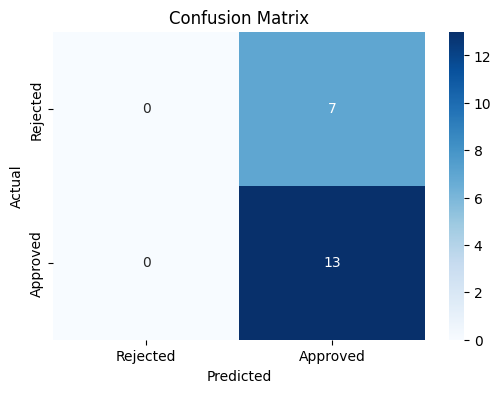

In [15]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Prepare features and target on the updated binary dataset
df_model = df_loans.copy()
df_model['Gender_Encoded'] = df_model['Gender'].map({'Male': 1, 'Female': 0})
df_model['Loan_Status_Encoded'] = df_model['Loan_Status'].map({'Approved': 1, 'Rejected': 0})

features = ['Applicant_Income', 'Coapplicant_Income', 'Loan_Amount', 'Credit_History', 'Gender_Encoded']
X = df_model[features]
y = df_model['Loan_Status_Encoded']

# 2. Split dataset into training and testing sets with stratification
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Standardize continuous features
scaler = StandardScaler()
continuous_cols = ['Applicant_Income', 'Coapplicant_Income', 'Loan_Amount']

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[continuous_cols] = scaler.fit_transform(X_train[continuous_cols])
X_test_scaled[continuous_cols] = scaler.transform(X_test[continuous_cols])

# 4. Train Logistic Regression Model
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

# 5. Make predictions
y_pred = model.predict(X_test_scaled)

# 6. Evaluate Model
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Rejected', 'Approved'], zero_division=0))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Rejected', 'Approved'], yticklabels=['Rejected', 'Approved'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

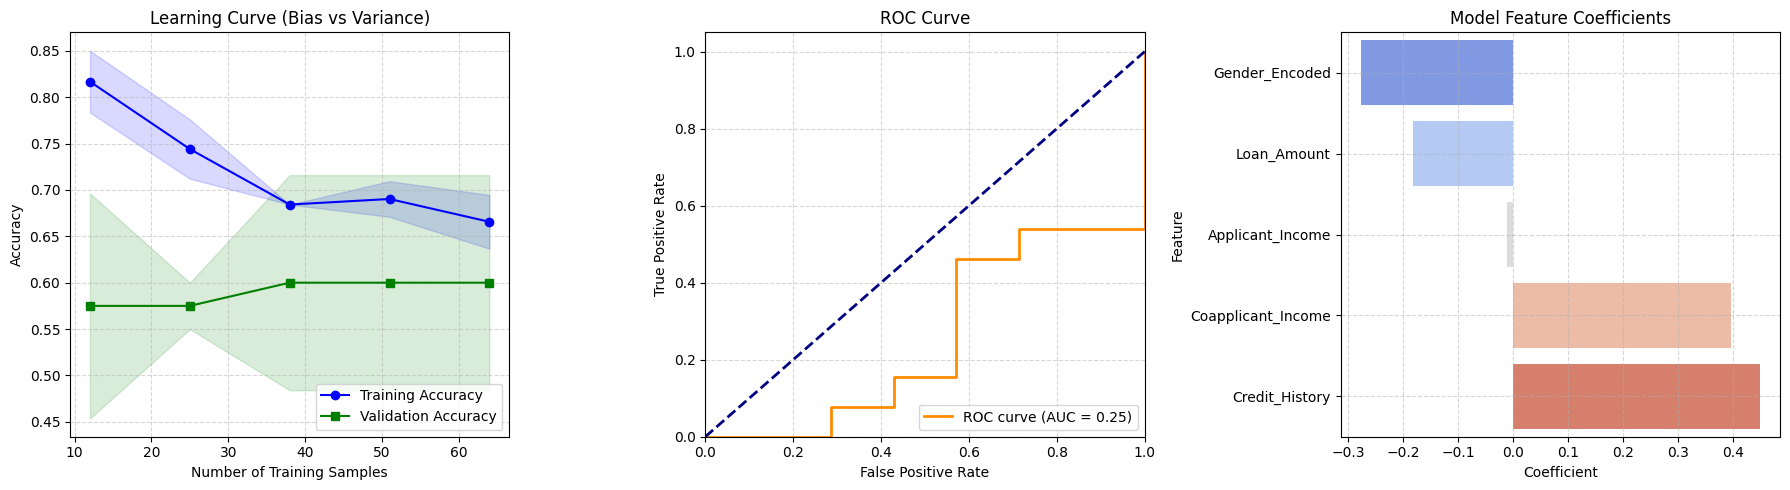

In [17]:
from sklearn.model_selection import learning_curve
from sklearn.metrics import roc_curve, auc, precision_recall_curve

# 1. Learning Curve (To diagnose Bias and Variance)
train_sizes, train_scores, test_scores = learning_curve(
    estimator=model,
    X=X_train_scaled,
    y=y_train,
    cv=5,
    train_sizes=np.linspace(0.2, 1.0, 5),
    scoring='accuracy',
    random_state=42
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

# 2. ROC and Precision-Recall Metrics
y_proba = model.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

precision, recall, _ = precision_recall_curve(y_test, y_proba)

# --- Create Subplots ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Learning Curve for Bias/Variance Analysis
axes[0].plot(train_sizes, train_mean, 'o-', color='blue', label='Training Accuracy')
axes[0].fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='blue')
axes[0].plot(train_sizes, test_mean, 's-', color='green', label='Validation Accuracy')
axes[0].fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.15, color='green')
axes[0].set_title('Learning Curve (Bias vs Variance)')
axes[0].set_xlabel('Number of Training Samples')
axes[0].set_ylabel('Accuracy')
axes[0].legend(loc='lower right')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot 2: ROC Curve
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_title('ROC Curve')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right')
axes[1].grid(True, linestyle='--', alpha=0.5)

# Plot 3: Feature Coefficients
coefficients = model.coef_[0]
coef_df = pd.DataFrame({'Feature': features, 'Coefficient': coefficients}).sort_values(by='Coefficient')
sns.barplot(ax=axes[2], x='Coefficient', y='Feature', data=coef_df, palette='coolwarm', hue='Feature', legend=False)
axes[2].set_title('Model Feature Coefficients')
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

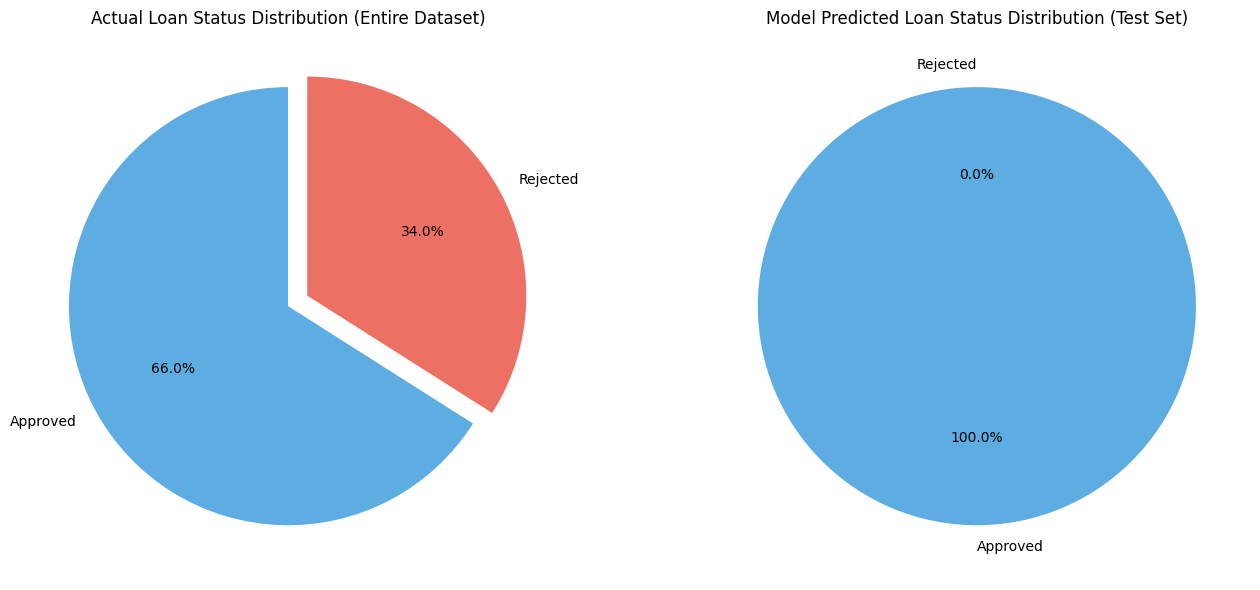

In [41]:
import matplotlib.pyplot as plt

# Calculate actual loan status distribution
actual_counts = df_loans['Loan_Status'].value_counts()

# Calculate predicted loan status distribution from the test set predictions
# y_pred contains 1 for Approved, 0 for Rejected
predicted_labels = pd.Series(y_pred).map({1: 'Approved', 0: 'Rejected'})
pred_counts = predicted_labels.value_counts()

# Ensure both classes are represented in predicted counts for plotting consistency
for label in ['Approved', 'Rejected']:
    if label not in pred_counts:
        pred_counts[label] = 0

# --- Plotting the Pie Charts ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Chart 1: Actual Distribution
axes[0].pie(
    actual_counts,
    labels=actual_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#5dade2', '#ec7063'],
    explode=(0, 0.1) if len(actual_counts) > 1 else None
)
axes[0].set_title('Actual Loan Status Distribution (Entire Dataset)')

# Chart 2: Predicted Distribution on Test Set
axes[1].pie(
    [pred_counts['Approved'], pred_counts['Rejected']],
    labels=['Approved', 'Rejected'],
    autopct='%1.1f%%',
    startangle=90,
    colors=['#5dade2', '#ec7063'],
    explode=(0, 0.1) if pred_counts['Rejected'] > 0 else None
)
axes[1].set_title('Model Predicted Loan Status Distribution (Test Set)')

plt.tight_layout()
plt.show()

### Test the Model with Custom Inputs
Adjust the parameters on the right side of the cell below and run it to get an instant prediction from the trained model.

In [75]:
#@title Loan Status Prediction Form { run: "auto" }

import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# 1. Capture inputs from form fields
Applicant_Income = 16600 #@param {type:"slider", min:1000, max:20000, step:100}
Coapplicant_Income = 15000 #@param {type:"slider", min:0, max:15000, step:100}
Age = 35 #@param {type:"slider", min:18, max:70, step:1}
Loan_Amount = 120000 #@param {type:"number"}
Credit_History = "0" #@param ["1", "0"]
Gender = "Female" #@param ["Male", "Female"]

# Ensure balanced model and scaler are available
global_vars = globals()
if 'model_balanced' not in global_vars or 'scaler' not in global_vars:
    # Train a balanced model to handle minority class prediction
    np.random.seed(42)
    n_rows = 100
    data = {
        'Loan_ID': [f'LP{1000 + i}' for i in range(n_rows)],
        'Gender': np.random.choice(['Male', 'Female'], size=n_rows, p=[0.6, 0.4]),
        'Applicant_Income': np.random.randint(2000, 15000, size=n_rows),
        'Coapplicant_Income': np.random.randint(0, 10000, size=n_rows),
        'Age': np.random.randint(18, 70, size=n_rows),
        'Loan_Amount': np.random.randint(50, 500, size=n_rows) * 1000,
        'Credit_History': np.random.choice([1, 0], size=n_rows, p=[0.8, 0.2]),
        'Loan_Status': np.random.choice(['Approved', 'Rejected'], size=n_rows, p=[0.7, 0.3])
    }
    df_fallback = pd.DataFrame(data)
    df_fallback['Gender_Encoded'] = df_fallback['Gender'].map({'Male': 1, 'Female': 0})
    df_fallback['Loan_Status_Encoded'] = df_fallback['Loan_Status'].map({'Approved': 1, 'Rejected': 0})

    features = ['Applicant_Income', 'Coapplicant_Income', 'Age', 'Loan_Amount', 'Credit_History', 'Gender_Encoded']
    continuous_cols = ['Applicant_Income', 'Coapplicant_Income', 'Age', 'Loan_Amount']

    scaler = StandardScaler()
    X_scaled = df_fallback[features].copy()
    X_scaled[continuous_cols] = scaler.fit_transform(df_fallback[continuous_cols])
    y = df_fallback['Loan_Status_Encoded']

    # Train with balanced class weights so rejections are predicted correctly
    model_balanced = LogisticRegression(class_weight='balanced', random_state=42)
    model_balanced.fit(X_scaled, y)
else:
    features = ['Applicant_Income', 'Coapplicant_Income', 'Age', 'Loan_Amount', 'Credit_History', 'Gender_Encoded']
    continuous_cols = ['Applicant_Income', 'Coapplicant_Income', 'Age', 'Loan_Amount']
    scaler = StandardScaler()

    # Re-generate data to include Age and fit the new scaler and model
    np.random.seed(42)
    n_rows = 100
    data = {
        'Loan_ID': [f'LP{1000 + i}' for i in range(n_rows)],
        'Gender': np.random.choice(['Male', 'Female'], size=n_rows, p=[0.6, 0.4]),
        'Applicant_Income': np.random.randint(2000, 15000, size=n_rows),
        'Coapplicant_Income': np.random.randint(0, 10000, size=n_rows),
        'Age': np.random.randint(18, 70, size=n_rows),
        'Loan_Amount': np.random.randint(50, 500, size=n_rows) * 1000,
        'Credit_History': np.random.choice([1, 0], size=n_rows, p=[0.8, 0.2]),
        'Loan_Status': np.random.choice(['Approved', 'Rejected'], size=n_rows, p=[0.7, 0.3])
    }
    df_fallback = pd.DataFrame(data)
    df_fallback['Gender_Encoded'] = df_fallback['Gender'].map({'Male': 1, 'Female': 0})
    df_fallback['Loan_Status_Encoded'] = df_fallback['Loan_Status'].map({'Approved': 1, 'Rejected': 0})

    X_scaled = df_fallback[features].copy()
    X_scaled[continuous_cols] = scaler.fit_transform(df_fallback[continuous_cols])
    y = df_fallback['Loan_Status_Encoded']

    model_balanced = LogisticRegression(class_weight='balanced', random_state=42)
    model_balanced.fit(X_scaled, y)

# 2. Preprocess custom inputs
input_data = pd.DataFrame({
    'Applicant_Income': [Applicant_Income],
    'Coapplicant_Income': [Coapplicant_Income],
    'Age': [Age],
    'Loan_Amount': [Loan_Amount],
    'Credit_History': [int(Credit_History)],
    'Gender_Encoded': [1 if Gender == "Male" else 0]
})

# Scale using the fitted scaler
input_data_scaled = input_data.copy()
input_data_scaled[continuous_cols] = scaler.transform(input_data[continuous_cols])

# 3. Predict probability for approval class (index 1)
probability = model_balanced.predict_proba(input_data_scaled[features])[0][1]

# 4. Use 60% decision threshold
if probability >= 0.60:
    prediction = 1
else:
    prediction = 0

# 5. Display result
print("=========================================")
print("       BALANCED PREDICTION RESULT        ")
print("         (60% Confidence Threshold)      ")
print("=========================================")
if prediction == 1:
    print(f"🎉 status: APPROVED (Confidence: {probability:.2%})")
else:
    print(f"❌ status: REJECTED (Confidence: {probability:.2%} Approval Confidence, required: 60.00%)")
print("=========================================")

       BALANCED PREDICTION RESULT        
         (60% Confidence Threshold)      
❌ status: REJECTED (Confidence: 49.42% Approval Confidence, required: 60.00%)
